FASHION IMAGE CLASSIFICATION SYSTEM

[1/4] Loading Dataset...
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images: 60000
Testing Images : 10000

[2/4] Building Neural Network...

[3/4] Training Model...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8094 - loss: 0.5381 - val_accuracy: 0.8532 - val_loss: 0.4047
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8537 - loss: 0.4040 - val_accuracy: 0.8640 - val_loss: 0.3775
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8651 - loss: 0.3686 - val_accuracy: 0.8745 - val_loss: 0.3397
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8727 - loss: 0.3472 - val_accuracy: 0.8747 - val_loss: 0.3415
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8768 - loss: 0.3331 - val_accuracy: 0.8838 - val_loss: 0.3316

[4/4] Evaluating Predictive System...

Test Accuracy: 87.35%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

PREDICTION RESULTS
Predicted: Ankle boot
Actual   : Ankle boot


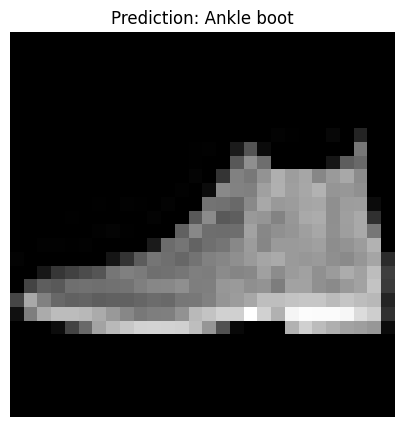

In [1]:
# ==========================================
# TENSORFLOW COMPUTER VISION CLASSIFICATION
# Fashion-MNIST Clothing Recognition System
# ==========================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("=" * 50)
print("FASHION IMAGE CLASSIFICATION SYSTEM")
print("=" * 50)

print("\n[1/4] Loading Dataset...")

fashion_mnist = tf.keras.datasets.fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

train_images = train_images / 255.0
test_images = test_images / 255.0

print(f"Training Images: {len(train_images)}")
print(f"Testing Images : {len(test_images)}")

print("\n[2/4] Building Neural Network...")

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n[3/4] Training Model...")

history = model.fit(
    train_images,
    train_labels,
    epochs=5,
    validation_split=0.1,
    verbose=1
)

print("\n[4/4] Evaluating Predictive System...")

test_loss, test_accuracy = model.evaluate(
    test_images,
    test_labels,
    verbose=0
)

print(f"\nTest Accuracy: {test_accuracy:.2%}")

predictions = model.predict(test_images)

class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]

sample_index = 0

predicted_class = np.argmax(
    predictions[sample_index]
)

actual_class = test_labels[sample_index]

print("\n" + "=" * 50)
print("PREDICTION RESULTS")
print("=" * 50)

print(
    f"Predicted: {class_names[predicted_class]}"
)

print(
    f"Actual   : {class_names[actual_class]}"
)

plt.figure(figsize=(5,5))

plt.imshow(
    test_images[sample_index],
    cmap='gray'
)

plt.title(
    f"Prediction: {class_names[predicted_class]}"
)

plt.axis('off')

plt.show()
